# 12 · Análisis posterior del detector final en test

**Este notebook se hizo después de la evaluación única del detector final (`11`) y no la cambia.** Es descriptivo: no se ajusta ni se elige nada, y los resultados de la hipótesis siguen siendo los de `11`. Si algo de lo que se ve acá sugiriera un cambio, haría falta otra base para evaluarlo, porque test ya no sirve para elegir.

**Resultado de `11`.** Con el detector final se cumplen P1 y P3, pero no P2, así que H no se sostiene. El detector final es la versión evaluada en `05` sin el filtro de Wiener en la EDR, y nada más.

**Qué se analiza.** El análisis sigue lo que pidió la devolución de la primera entrega para los resultados:
- figuras de los resultados, no solo tablas;
- el nivel de cada análisis dicho de forma explícita;
- tablas con intervalos de confianza por persona;
- los errores explicados con las señales;
- y conclusiones atadas a P1–P3.

| Nivel | Unidad | Secciones |
|---|---|---|
| Minuto | los 8844 minutos evaluados | 2 |
| Noche | los 20 registros | 3, 4, 6, 7 y 8 |
| Persona | las 10 personas; es la unidad del bootstrap | 5 |
| Categoría | A (apnea), B (dudosa) y C (control), según PhysioNet | 2 y 3 |
| Base | test contra desarrollo | 9 |

Se usan las mismas tablas por minuto y los mismos parámetros fijos que en `11`, y se verifica que se reproducen sus resultados. Para la comparación con Wiener, la versión evaluada se recalcula con `docs/parametros_test.json`, igual que en `11` §4.1.

In [1]:
import json
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.config import ECG_FILTER, MIN_MINUTES_PER_CLASS, MINUTE_MAX_CORRECTED, SPLIT_CSV, WIENER_TEMPLATE
from src.data import load_apnea_labels, load_ecg, load_record_info
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.preprocessing.wiener import estimate_psds, extract_realizations
from src.qrs.beats import record_beats
from src.detector_final import cargar_params, tabla_final, verificar_qrs
from src.evaluation.cv import auc, metricas
from src.evaluation.metrics import category_from_minutes
from src.features.detector import c_score, evaluable, load_params, minute_table, youden_threshold
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, save, setup, shade_apnea
from src.viz.visor_data import analizar_noche, ventana_minuto

setup()
P = cargar_params()
verificar_qrs(P)
P_EV = load_params(ROOT / "docs" / "parametros_test.json")
RES = json.loads((ROOT / "docs" / "resultados_test_final.json").read_text())
RES_05 = json.loads((ROOT / "docs" / "resultados_test.json").read_text())

split = pd.read_csv(SPLIT_CSV)
SUJETO, CATEG = split.set_index("record").subject, split.set_index("record").category
TEST = split[split.set == "test"].record.tolist()
DEV = split[split.set == "dev"].record.tolist()
info = load_record_info().set_index("record")
PERFIL = info[["age", "sex", "height_cm", "weight_kg"]].assign(IMC=lambda d_: d_.weight_kg / (d_.height_cm / 100) ** 2)


def tabla(rec):
    tab, _ = tabla_final(rec, params=P)
    return tab


def tabla_evaluada(rec):
    """La versión evaluada en 05 (con Wiener): valores por defecto de src/config.py y parametros_test.json."""
    tab = minute_table(rec)
    tab["termino_rr"] = (tab.P_RR - P_EV["mu1"]) / P_EV["s1"]
    tab["termino_edr"] = P_EV["w"] * (tab.EDR_noche - P_EV["mu2"]) / P_EV["s2"]
    tab["C"] = c_score(tab, P_EV)
    tab["decision"] = (tab.C > P_EV["umbral"]).astype(int)
    tab["evaluado"] = evaluable(tab)
    return tab


with ProcessPoolExecutor(4) as ex:
    T = pd.concat(list(ex.map(tabla, TEST)), ignore_index=True)
    T_EV = pd.concat(list(ex.map(tabla_evaluada, TEST)), ignore_index=True)
    D = pd.concat(list(ex.map(tabla, DEV)), ignore_index=True)
for X_ in (T, T_EV, D):
    X_["subject"], X_["category"] = X_.record.map(SUJETO), X_.record.map(CATEG)

COLS = ["P_RR", "P_EDR", "F", "C"]
et = T[T.evaluado].dropna(subset=COLS).reset_index(drop=True)
ed = D[D.evaluado].dropna(subset=COLS).reset_index(drop=True)
et_ev = T_EV[T_EV.evaluado].dropna(subset=COLS).reset_index(drop=True)
y_t, d_t = et.label.to_numpy(), et.decision.to_numpy()

# Control: son las mismas tablas que en 11 y en 05
assert len(et) == RES["minutos_evaluados"] == len(et_ev) == RES_05["minutos_evaluados"]
assert np.isclose(auc(et.C, et.label), RES["predicciones"]["P3 · AUC de C con todos los minutos"]["valor"], rtol=0, atol=1e-12)
assert np.isclose(auc(et_ev.C, et_ev.label), RES_05["predicciones"]["P3 · AUC de C con todos los minutos"]["valor"], rtol=0, atol=1e-12)
print(f"tablas de 11 y 05 reproducidas: {len(et)} minutos evaluados de {len(T)}, {et.record.nunique()} noches, {et.subject.nunique()} personas")

tablas de 11 y 05 reproducidas: 8844 minutos evaluados de 9639, 20 noches, 10 personas


## 1. El resultado de `11`, en una tabla (nivel base)

Se leen de `docs/resultados_test_final.json`; no se recalculan.

In [2]:
pd.DataFrame([{"medida": k, "test": v["valor"], "IC 95 % (bootstrap por persona)": v["ic95"],
               "se cumple": v.get("se_cumple", "")} for k, v in {**RES["predicciones"], **RES["clasificacion_C"]}.items()]
             ).set_index("medida").round(3)

,test,IC 95 % (bootstrap por persona),se cumple
medida,,,
P1 · AUC dentro de la noche del RR (media),0.869,0.827 a 0.930,True
P2 · ρ entre el nivel EDR de la noche y el % de apnea,0.531,-0.152 a 0.732,False
P3 · AUC de C con todos los minutos,0.827,0.627 a 0.937,True
sensibilidad,0.699,0.303 a 0.905,
especificidad,0.833,0.727 a 0.927,
exactitud,0.775,0.692 a 0.862,


## 2. Nivel minuto

### 2.1 Matriz de confusión

Cada minuto evaluado tiene una etiqueta (apnea o normal, puesta por un experto a partir de la polisomnografía) y una decisión del detector (C por encima o por debajo del umbral fijado en desarrollo).

In [3]:
etq = pd.Series(np.where(y_t == 1, "apnea", "normal"), name="etiqueta")
dec = pd.Series(np.where(d_t == 1, "apnea", "normal"), name="decisión del detector")
mc = pd.crosstab(etq, dec, margins=True, margins_name="total")
print(f"de {int((y_t == 1).sum())} minutos con apnea se detectan {int(((d_t == 1) & (y_t == 1)).sum())}; "
      f"de {int((y_t == 0).sum())} normales se marcan como apnea {int(((d_t == 1) & (y_t == 0)).sum())} (falsas alarmas)")
for nombre, sel in (("perdidos (apnea no detectada)", (y_t == 1) & (d_t == 0)), ("falsas alarmas", (y_t == 0) & (d_t == 1))):
    por = et[sel].groupby("record").size().sort_values(ascending=False)
    print(f"{nombre}: {por.sum()} minutos; las 5 noches con más concentran el {100 * por.head(5).sum() / por.sum():.0f} % "
          f"({', '.join(f'{r_} {n_}' for r_, n_ in por.head(5).items())})")
mc

de 3822 minutos con apnea se detectan 2671; de 5022 normales se marcan como apnea 839 (falsas alarmas)
perdidos (apnea no detectada): 1151 minutos; las 5 noches con más concentran el 82 % (a11 222, x26 205, a06 187, x15 185, x13 147)
falsas alarmas: 839 minutos; las 5 noches con más concentran el 61 % (b05 171, a07 106, c08 82, x30 80, x11 73)


decisión del detector,apnea,normal,total
etiqueta,,,
apnea,2671,1151,3822
normal,839,4183,5022
total,3510,5334,8844


**Qué se ve.**
- Se detectan 2671 de los 3822 minutos con apnea (70 %), y 839 de los 5022 normales se marcan como apnea (17 %).
- **Los errores no están repartidos: vienen en noches enteras.**
  - Las 5 noches con más minutos perdidos concentran el 82 % de los perdidos: a11, x26, a06, x15 y x13, de tres personas.
  - Las 5 noches con más falsas alarmas concentran el 61 % de ellas: b05, a07, c08, x30 y x11.

### 2.2 Por categoría de la noche

Las mismas medidas, separando los minutos según la categoría de su noche. En las noches B (2 personas) y C (3 personas) hay muy pocas personas, así que estas cifras son descriptivas, sin intervalo.

In [4]:
filas = []
for cat, g_ in et.groupby("category"):
    m_ = metricas(g_.label, g_.decision)
    filas.append({"categoría": cat, "noches": g_.record.nunique(), "personas": g_.subject.nunique(), "minutos": len(g_),
                  "con apnea (%)": 100 * g_.label.mean(), "marcados (%)": 100 * g_.decision.mean(),
                  "sensibilidad": m_["sensibilidad"] if g_.label.sum() else np.nan, "especificidad": m_["especificidad"],
                  "exactitud": m_["exactitud"]})
pd.DataFrame(filas).set_index("categoría").round(3)

,noches,personas,minutos,con apnea (%),marcados (%),sensibilidad,especificidad,exactitud
categoría,,,,,,,,
A,12,6,6039,62.014,50.356,0.695,0.810,0.739
B,3,2,1249,6.085,28.022,0.882,0.759,0.766
C,5,3,1556,0.064,7.648,0.000,0.923,0.923


**Qué se ve.**
- **Noches A:** se detecta el 70 % de los minutos con apnea y se marca el 19 % de los normales.
- **Noches B** (6 % de apnea): se marca el 28 % de los minutos. Es donde más sobreestima, casi todo por b05.
- **Controles:** se marca el 7,6 % de los minutos (especificidad 0,923). La sensibilidad es 0 porque hay un solo minuto con apnea (en x24) y no se detecta.

### 2.3 Cómo se reparte C

C en los minutos con apnea y en los normales, en test y en desarrollo, con el umbral. Cuanto más se superponen las dos distribuciones, más minutos quedan del lado equivocado. A la derecha, la curva ROC de C, F y el RR solo en test, con el punto de cada umbral fijado en desarrollo.

desarrollo: mediana de C en apnea 1.35, en normales -0.78; minutos a menos de 0,5 del umbral: 21.5 %
test: mediana de C en apnea 1.19, en normales -0.50; minutos a menos de 0,5 del umbral: 26.5 %


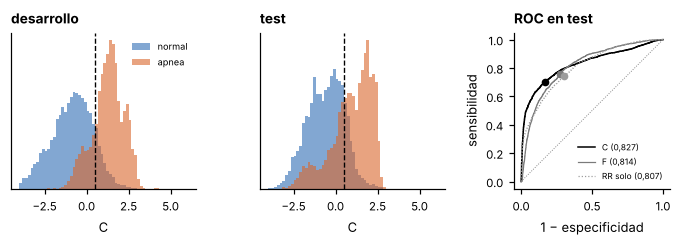

In [5]:
U = {"C": P["umbral"], "F": youden_threshold(ed.F.to_numpy(), ed.label.to_numpy()),
     "RR solo": youden_threshold(ed.P_RR.to_numpy(), ed.label.to_numpy())}
COL = {"C": "C", "F": "F", "RR solo": "P_RR"}
assert all(np.isclose(U[k], RES["umbrales_desarrollo"][k]) for k in U)


def roc(x, y):
    o = np.argsort(-np.asarray(x)); yy = np.asarray(y)[o]
    return np.r_[0, np.cumsum(1 - yy) / (1 - yy).sum()], np.r_[0, np.cumsum(yy) / yy.sum()]


fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1, 1, 0.9]})
bins = np.linspace(-4, 6, 61)
for a_, (tab_, nombre) in zip(ax[:2], ((ed, "desarrollo"), (et, "test"))):
    a_.hist(tab_.C[tab_.label == 0], bins=bins, density=True, color=NORMAL, alpha=0.6, label="normal")
    a_.hist(tab_.C[tab_.label == 1], bins=bins, density=True, color=APNEA, alpha=0.6, label="apnea")
    a_.axvline(P["umbral"], color="black", ls="--", lw=0.9)
    a_.set(xlabel="C", title=nombre, yticks=[])
ax[0].legend(fontsize=6, loc="upper right")
for feat, color in (("C", "black"), ("F", GRIS), ("RR solo", "#9C9C9C")):
    fpr, tpr = roc(et[COL[feat]], y_t)
    ax[2].plot(fpr, tpr, color=color, lw=1 if feat == "C" else 0.8, ls="-" if feat != "RR solo" else ":",
               label=f"{feat} ({auc(et[COL[feat]], y_t):.3f})".replace(".", ","))
    m_ = metricas(y_t, (et[COL[feat]] > U[feat]).astype(int))
    ax[2].plot(1 - m_["especificidad"], m_["sensibilidad"], "o", color=color, ms=4)
ax[2].plot([0, 1], [0, 1], ":", color=GRIS, lw=0.6)
ax[2].set(xlabel="1 − especificidad", ylabel="sensibilidad", title="ROC en test", aspect="equal")
ax[2].legend(fontsize=5.5, loc="lower right")
fig.tight_layout()
save(fig, "12_minutos")
for nombre, tab_ in (("desarrollo", ed), ("test", et)):
    print(f"{nombre}: mediana de C en apnea {tab_.C[tab_.label == 1].median():.2f}, en normales {tab_.C[tab_.label == 0].median():.2f}; "
          f"minutos a menos de 0,5 del umbral: {100 * (abs(tab_.C - P['umbral']) < 0.5).mean():.1f} %")

**Qué se ve.**
- **En test las dos distribuciones se superponen más que en desarrollo.** El 26,5 % de los minutos queda a menos de 0,5 del umbral, contra 21,5 %. La mediana de C baja en los minutos con apnea (1,19 contra 1,35) y sube en los normales (−0,50 contra −0,78).
- **Los minutos con apnea de test tienen un segundo grupo con C bajo,** alrededor de −1,5. Son los de las noches subestimadas (§6).
- **En la ROC, C queda por encima de F y del RR solo en la zona de pocas falsas alarmas,** que es donde cae su umbral. Con todos los umbrales las tres curvas se parecen: AUC 0,827, 0,814 y 0,807, sin diferencia demostrable (`11` §4.2).

## 3. Nivel noche

### 3.1 Cada noche

Para cada noche: cuánta apnea tiene y cuánta marca el detector, y el **término de la EDR** y la **vara del RR**. El término de la EDR es el mismo en toda la noche. Un minuto se marca si su término RR supera la vara: **vara = umbral − término EDR**. Si el nivel de la EDR de la noche es bajo, la vara queda alta, y al revés. La categoría estimada aplica a los minutos marcados la misma regla que define la categoría con las etiquetas (A ≥ 100 minutos de apnea, B de 5 a 99, C menos de 5; `src/split.py`).

In [6]:
def por_noche(tab_all, e):
    filas = []
    for r_, g_ in tab_all.groupby("record"):
        ev = e[e.record == r_]
        y_, d_ = ev.label.to_numpy(), ev.decision.to_numpy()
        n1, n0 = int((y_ == 1).sum()), int((y_ == 0).sum())
        filas.append({"record": r_, "persona": SUJETO[r_], "categoría": CATEG[r_], "minutos": len(g_),
                      "evaluados (%)": 100 * len(ev) / len(g_), "apnea real (%)": 100 * y_.mean(),
                      "marcado (%)": 100 * d_.mean(), "error (puntos)": 100 * (d_.mean() - y_.mean()),
                      "sensibilidad": ((d_ == 1) & (y_ == 1)).sum() / n1 if n1 else np.nan,
                      "especificidad": ((d_ == 0) & (y_ == 0)).sum() / n0 if n0 else np.nan,
                      "exactitud": (d_ == y_).mean(),
                      "AUC dentro de la noche": auc(ev.P_RR, ev.label) if min(n1, n0) >= MIN_MINUTES_PER_CLASS else np.nan,
                      "nivel EDR": g_.EDR_noche.iloc[0], "término EDR": g_.termino_edr.iloc[0],
                      "vara del RR": P["umbral"] - g_.termino_edr.iloc[0] if "termino_edr" in g_ else np.nan,
                      "término RR, minutos normales": ev[ev.label == 0].termino_rr.median(),
                      "término RR, minutos con apnea": ev[ev.label == 1].termino_rr.median(),
                      "categoría (regla, etiquetas)": category_from_minutes(n1),
                      "categoría estimada": category_from_minutes(int(d_.sum()))})
    return pd.DataFrame(filas).set_index("record")


NT, ND = por_noche(T, et), por_noche(D, ed)
NT.sort_values("error (puntos)").round(2)

,persona,categoría,minutos,evaluados (%),apnea real (%),marcado (%),error (puntos),sensibilidad,especificidad,exactitud,AUC dentro de la noche,nivel EDR,término EDR,vara del RR,"término RR, minutos normales","término RR, minutos con apnea","categoría (regla, etiquetas)",categoría estimada
record,,,,,,,,,,,,,,,,,,
a11,S10,A,464,100.00,47.84,0.00,-47.84,0.00,1.00,0.52,0.85,-2.84,-1.42,1.90,-1.07,-0.44,A,C
x15,S06,A,496,100.00,40.32,3.23,-37.10,0.08,1.00,0.62,0.83,-2.28,-0.49,0.97,-1.00,-0.06,A,B
x26,S28,A,516,99.81,66.60,29.51,-37.09,0.40,0.92,0.57,0.86,-1.89,0.18,0.30,-0.98,0.15,A,A
a06,S06,A,506,100.00,40.71,5.34,-35.38,0.09,0.97,0.61,0.74,-2.36,-0.62,1.10,-0.75,0.02,A,B
x13,S28,A,504,100.00,57.54,31.55,-25.99,0.49,0.93,0.68,0.88,-1.82,0.28,0.20,-0.99,0.20,A,A
x01,S07,A,509,100.00,73.67,60.51,-13.16,0.74,0.78,0.75,0.83,-1.78,0.35,0.13,-0.40,0.55,A,A
x24,S25,C,416,99.04,0.24,0.00,-0.24,0.00,1.00,1.00,NaN,-2.89,-1.49,1.97,-0.28,1.02,C,C
c04,S21,C,464,27.16,0.00,1.59,1.59,NaN,0.98,0.98,NaN,-2.15,-0.26,0.74,-0.66,NaN,C,C
x31,S29,A,553,100.00,92.95,98.01,5.06,1.00,0.28,0.95,0.97,-1.70,0.49,-0.01,0.63,1.81,A,A


PosixPath('/home/user/TP-PSB-G8/informe/figuras/12_error_por_noche.png')

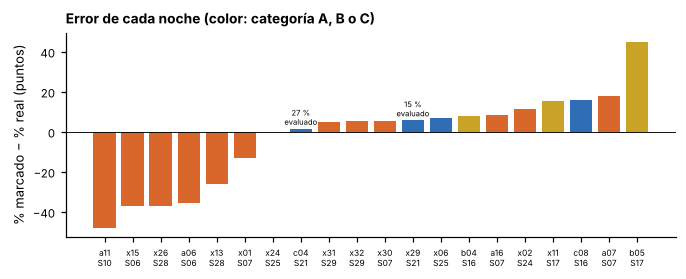

In [7]:
o_ = NT.sort_values("error (puntos)")
fig, ax = plt.subplots(figsize=(ANCHO, 2.6))
ax.bar(range(len(o_)), o_["error (puntos)"], color=[COLORES_CAT[c] for c in o_["categoría"]])
ax.set_xticks(range(len(o_)), [f"{r_}\n{f_.persona}" for r_, f_ in o_.iterrows()], fontsize=5.5)
for k, (r_, f_) in enumerate(o_.iterrows()):
    if f_["evaluados (%)"] < 50:
        ax.text(k, f_["error (puntos)"] + 2, f"{f_['evaluados (%)']:.0f} %\nevaluado", ha="center", fontsize=5)
ax.axhline(0, color="black", lw=0.6)
ax.set(ylabel="% marcado − % real (puntos)", title="Error de cada noche (color: categoría A, B o C)")
fig.tight_layout()
save(fig, "12_error_por_noche")

**Qué se ve.**
- **Cinco noches con apnea se subestiman mucho, y son de tres personas:** a11 (S10), x15 y a06 (S06), y x26 y x13 (S28).
  - En las cinco, el término RR de los minutos normales está cerca de −1: el RR de esas personas oscila poco en la banda.
  - En los minutos con apnea el RR sube, pero queda cerca de la vara o por debajo.
- **En a11, además, el nivel de la EDR es muy bajo** (término −1,42). La vara queda en 1,90 y ningún minuto la alcanza.
- **La noche más sobreestimada es b05** (14 % real, 59 % marcado). Su término EDR es el más alto de test (+0,87), y la vara queda en −0,39, por debajo del RR de casi toda la noche.
- Le siguen a07 (+18 puntos), c08 (+16) y x11 (+15).

### 3.2 La categoría de cada noche

Es un resultado secundario: el detector no es un diagnóstico (`objetivos_hipotesis.md`, alcance). Se compara la categoría estimada con la que da la misma regla aplicada a las etiquetas de los minutos evaluados.

In [8]:
cat_tab = pd.crosstab(NT["categoría (regla, etiquetas)"], NT["categoría estimada"], margins=True, margins_name="total")
print(f"coinciden {int((NT['categoría (regla, etiquetas)'] == NT['categoría estimada']).sum())} de {len(NT)} noches")
print("no coinciden:", ", ".join(f"{r_} ({f_['categoría (regla, etiquetas)']}→{f_['categoría estimada']})"
                                 for r_, f_ in NT.iterrows() if f_["categoría (regla, etiquetas)"] != f_["categoría estimada"]))
cat_tab

coinciden 14 de 20 noches
no coinciden: a06 (A→B), a11 (A→C), b05 (B→A), c08 (C→B), x06 (C→B), x15 (A→B)


categoría estimada,A,B,C,total
"categoría (regla, etiquetas)",,,,
A,9,2,1,12
B,1,2,0,3
C,0,2,3,5
total,10,6,4,20


**Qué se ve.** Coinciden 14 de las 20 noches. Los errores de categoría salen de las mismas noches de §3.1:
- tres noches A se estiman con una categoría menor: a11 como C, a06 y x15 como B;
- b05 (B) se estima como A;
- dos controles (c08 y x06) se estiman como B.

### 3.3 Minutos de apnea por hora

La cantidad de apnea de cada noche, en minutos por hora evaluada, estimada contra real. Es lo que vería un médico como resumen de la noche.

In [9]:
mph = pd.DataFrame({"real (min/h)": NT["apnea real (%)"] * 0.6, "estimado (min/h)": NT["marcado (%)"] * 0.6,
                    "categoría": NT["categoría"]})
r_mph = spearmanr(mph["real (min/h)"], mph["estimado (min/h)"])[0]
print(f"ρ de Spearman entre real y estimado: {r_mph:.3f} (es el ρ por noche de 11) · "
      f"error absoluto mediano: {np.median(abs(mph['estimado (min/h)'] - mph['real (min/h)'])):.1f} min/h")
mph.sort_values("real (min/h)").round(1)

ρ de Spearman entre real y estimado: 0.734 (es el ρ por noche de 11) · error absoluto mediano: 7.4 min/h


,real (min/h),estimado (min/h),categoría
record,,,
c04,0.0,1.0,C
c08,0.0,9.7,C
x06,0.0,4.2,C
x29,0.0,3.5,C
x24,0.1,0.0,C
b04,1.4,6.3,B
x11,1.7,10.9,B
b05,8.4,35.4,B
x15,24.2,1.9,A


**Qué se ve.**
- El orden entre noches se mantiene (ρ = 0,734), con un error absoluto mediano de 7,4 minutos por hora.
- Las noches subestimadas tienen entre 24 y 40 minutos de apnea por hora y se estiman entre 0 y 19.
- b05 tiene 8 minutos por hora y se estiman 35.

### 3.4 P1 noche por noche

El AUC dentro de la noche del RR, en las 13 noches que tienen al menos 20 minutos de cada tipo. Mide si el RR ordena los minutos de la noche (apnea arriba, normales abajo), sin usar el umbral.

In [10]:
p1 = NT.dropna(subset=["AUC dentro de la noche"])[["persona", "categoría", "AUC dentro de la noche", "error (puntos)"]]
assert np.isclose(p1["AUC dentro de la noche"].mean(), RES["predicciones"]["P1 · AUC dentro de la noche del RR (media)"]["valor"])
print(f"media {p1['AUC dentro de la noche'].mean():.3f} (desarrollo {ND['AUC dentro de la noche'].mean():.3f}); "
      f"mínimo {p1['AUC dentro de la noche'].min():.3f}; noches con AUC < 0,8: {int((p1['AUC dentro de la noche'] < 0.8).sum())}")
p1.sort_values("AUC dentro de la noche").round(3)

media 0.869 (desarrollo 0.908); mínimo 0.739; noches con AUC < 0,8: 2


,persona,categoría,AUC dentro de la noche,error (puntos)
record,,,,
a06,S06,A,0.739,-35.375
x30,S07,A,0.795,5.501
a07,S07,A,0.819,17.787
x01,S07,A,0.831,-13.163
x15,S06,A,0.832,-37.097
b05,S17,B,0.843,45.000
a11,S10,A,0.845,-47.845
x26,S28,A,0.857,-37.087
x13,S28,A,0.879,-25.992


**Qué se ve.**
- **El RR ordena bien todas las noches.** Todos los AUC son ≥ 0,739, y solo 2 quedan por debajo de 0,8 (a06 y x30).
- **Las noches subestimadas tienen AUC altos:** a11 0,845, x15 0,832 y x26 0,857. El RR ordena bien sus minutos, así que el problema no está en el orden dentro de la noche sino en dónde queda la vara (§6).

## 4. P2 en detalle: por qué falla

P2 pide que el nivel nocturno de la EDR crezca con el % de minutos con apnea de la noche, con un intervalo que no incluya el 0. En test, ρ = 0,531 con IC −0,152 a 0,732.

### 4.1 El nivel de la EDR de cada noche

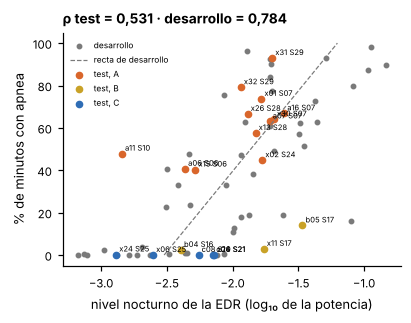

In [11]:
recta = np.polyfit(ND["apnea real (%)"], ND["nivel EDR"], 1)
fig, ax = plt.subplots(figsize=(3.8, 3.0))
ax.scatter(ND["nivel EDR"], ND["apnea real (%)"], s=8, color=GRIS, label="desarrollo")
xx = np.linspace(0, 100, 2)
ax.plot(np.polyval(recta, xx), xx, color=GRIS, lw=0.8, ls="--", label="recta de desarrollo")
for cat, g_ in NT.groupby("categoría"):
    ax.scatter(g_["nivel EDR"], g_["apnea real (%)"], s=16, color=COLORES_CAT[cat], label=f"test, {cat}")
for r_, f_ in NT.iterrows():
    ax.annotate(f"{r_} {f_.persona}", (f_["nivel EDR"], f_["apnea real (%)"]), fontsize=5, xytext=(2, 2), textcoords="offset points")
rho_t, rho_d = spearmanr(NT["nivel EDR"], NT["apnea real (%)"])[0], spearmanr(ND["nivel EDR"], ND["apnea real (%)"])[0]
ax.set(xlabel="nivel nocturno de la EDR (log₁₀ de la potencia)", ylabel="% de minutos con apnea",
       title=f"ρ test = {rho_t:.3f} · desarrollo = {rho_d:.3f}".replace(".", ","))
ax.legend(fontsize=5.5, loc="upper left")
fig.tight_layout()
save(fig, "12_p2_noches")
assert np.isclose(rho_t, RES["predicciones"]["P2 · ρ entre el nivel EDR de la noche y el % de apnea"]["valor"])

**Qué se ve.**
- ρ = 0,531 en test, contra 0,784 en desarrollo con estas mismas definiciones.
- **Como en desarrollo,** los controles quedan abajo (−2,9 a −2,1) y la mayoría de las noches A arriba (−1,9 a −1,6).
- **Dos excepciones fuertes:**
  - a11, con 48 % de apnea, tiene el nivel de un control (−2,84);
  - b05, con 14 %, tiene el nivel más alto de todo test (−1,47). x11 (3 %), de la misma persona, también queda entre las noches A.
- **Entre las noches A, el nivel casi no cambia con la cantidad de apnea.**

### 4.2 Qué personas mueven el intervalo

El intervalo de `11` sale de sortear personas con reposición. Se reproducen exactamente los mismos sorteos (misma semilla y mismo orden que en `11`) y se mira qué personas aparecen en los sorteos donde ρ queda bajo. Además, el ρ quitando cada persona.

In [12]:
rng = np.random.default_rng(2026)


def sorteos(personas, n=4000):
    personas = np.unique(personas)
    return [rng.choice(personas, len(personas)) for _ in range(n)]


def indices(suj, sorteo):
    return np.concatenate([np.flatnonzero(suj == u) for u in sorteo])


dentro = pd.DataFrame([{"record": r_, "subject": SUJETO[r_]} for r_, g_ in et.groupby("record")
                       if min((g_.label == 1).sum(), (g_.label == 0).sum()) >= MIN_MINUTES_PER_CLASS])
_ = sorteos(dentro.subject.to_numpy())                   # P1 en 11: se sortea primero, igual que allá
niv = et.groupby("record").agg(EDR_noche=("EDR_noche", "first"), frac=("label", "mean"), subject=("subject", "first"))
s2 = niv.subject.to_numpy()
SORT2 = sorteos(s2)
b2 = np.array([spearmanr(niv.EDR_noche.to_numpy()[i], niv.frac.to_numpy()[i])[0] for i in (indices(s2, so) for so in SORT2)])
ic2 = "{:.3f} a {:.3f}".format(*np.nanpercentile(b2, [2.5, 97.5]))
assert ic2 == RES["predicciones"]["P2 · ρ entre el nivel EDR de la noche y el % de apnea"]["ic95"], ic2
print("intervalo de 11 reproducido:", ic2, f"· sorteos con ρ ≤ 0: {100 * np.mean(b2 <= 0):.1f} %")

veces = pd.DataFrame([{u: int((so == u).sum()) for u in np.unique(s2)} for so in SORT2])
bajo = b2 <= np.nanpercentile(b2, 10)
apar = pd.DataFrame({"veces por sorteo (todos)": veces.mean(), "veces por sorteo (10 % con ρ más bajo)": veces[bajo].mean()})
apar["ρ sin esa persona"] = [spearmanr(niv[niv.subject != u].EDR_noche, niv[niv.subject != u].frac)[0] for u in apar.index]
apar["noches"] = [", ".join(niv.index[niv.subject == u]) for u in apar.index]
apar.sort_values("veces por sorteo (10 % con ρ más bajo)", ascending=False).round(3)

intervalo de 11 reproducido: -0.152 a 0.732 · sorteos con ρ ≤ 0: 5.2 %


,veces por sorteo (todos),veces por sorteo (10 % con ρ más bajo),ρ sin esa persona,noches
S17,1.000,1.710,0.670,"b05, x11"
S10,1.014,1.562,0.584,a11
S06,1.025,1.325,0.558,"a06, x15"
S24,0.997,1.140,0.542,x02
S21,1.000,0.970,0.499,"c04, x29"
S28,0.978,0.835,0.506,"x13, x26"
S16,1.000,0.800,0.473,"b04, c08"
S29,0.991,0.662,0.504,"x31, x32"
S25,0.997,0.528,0.437,"x06, x24"
S07,0.998,0.468,0.407,"a07, a16, x01, x30"


**Qué se ve.**
- Se reproducen exactamente los sorteos y el intervalo de `11`. En el 5,2 % de los sorteos ρ ≤ 0.
- **En el 10 % de los sorteos con ρ más bajo aparecen más seguido tres personas:**
  - S17 (b05 y x11): 1,71 veces por sorteo, contra 1,0 en todos los sorteos;
  - S10 (a11): 1,56 veces;
  - S06 (a06 y x15): 1,33 veces.
- **Sin S17, ρ = 0,670;** sin S10, 0,584; sin S06, 0,558.
- **La persona que más sostiene la relación es S07,** con 4 noches A: sin ella, ρ baja a 0,407.

### 4.3 Con y sin Wiener, noche por noche

La única diferencia entre las dos versiones es el Wiener en la EDR, así que todo lo que cambia en P2 viene del nivel de la EDR de cada noche. Se comparan los dos niveles (en log₁₀ de la potencia) y la posición de cada noche entre las 20.

In [13]:
niv_ev = et_ev.groupby("record").agg(EDR_noche=("EDR_noche", "first"))
w_ = pd.DataFrame({"persona": NT.persona, "categoría": NT["categoría"], "apnea real (%)": NT["apnea real (%)"],
                   "nivel con Wiener": niv_ev.EDR_noche, "nivel sin Wiener": NT["nivel EDR"]})
w_["cambio"] = w_["nivel sin Wiener"] - w_["nivel con Wiener"]
w_["puesto con Wiener"] = w_["nivel con Wiener"].rank().astype(int)
w_["puesto sin Wiener"] = w_["nivel sin Wiener"].rank().astype(int)
w_["puesto por % de apnea"] = w_["apnea real (%)"].rank().astype(int)
rho_w = spearmanr(w_["nivel con Wiener"], w_["apnea real (%)"])[0]
assert np.isclose(rho_w, RES_05["predicciones"]["P2 · ρ entre el nivel EDR de la noche y el % de apnea"]["valor"])
print(f"ρ con % de apnea: con Wiener {rho_w:.3f}, sin Wiener {rho_t:.3f} · ρ entre los dos niveles: "
      f"{spearmanr(w_['nivel con Wiener'], w_['nivel sin Wiener'])[0]:.3f} · cambio mediano del nivel: {w_.cambio.median():+.3f}")
w_.sort_values("apnea real (%)").round(3)

ρ con % de apnea: con Wiener 0.658, sin Wiener 0.531 · ρ entre los dos niveles: 0.481 · cambio mediano del nivel: +0.108


,persona,categoría,apnea real (%),nivel con Wiener,nivel sin Wiener,cambio,puesto con Wiener,puesto sin Wiener,puesto por % de apnea
record,,,,,,,,,
c04,S21,C,0.000,-2.294,-2.148,0.146,9,8,2
c08,S16,C,0.000,-2.182,-2.259,-0.077,13,7,2
x06,S25,C,0.000,-2.799,-2.605,0.194,5,3,2
x29,S21,C,0.000,-3.545,-2.140,1.405,1,9,2
x24,S25,C,0.243,-2.974,-2.885,0.088,3,1,5
b04,S16,B,2.392,-2.443,-2.393,0.050,7,4,6
x11,S17,B,2.882,-2.767,-1.763,1.004,6,15,7
b05,S17,B,13.947,-3.288,-1.468,1.819,2,20,8
x15,S06,A,40.323,-2.290,-2.283,0.007,10,6,9


PosixPath('/home/user/TP-PSB-G8/informe/figuras/12_p2_wiener.png')

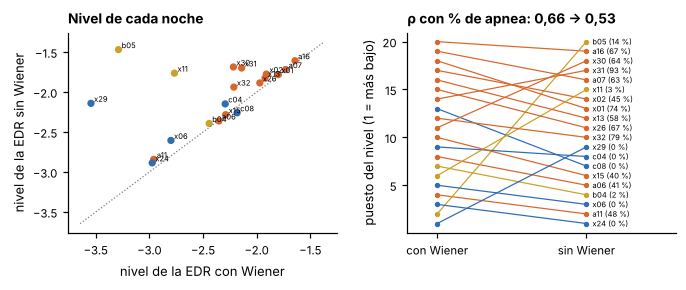

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.7))
ax[0].scatter(w_["nivel con Wiener"], w_["nivel sin Wiener"], s=14, c=[COLORES_CAT[c] for c in w_["categoría"]])
lim = [min(w_[["nivel con Wiener", "nivel sin Wiener"]].min()) - 0.1, max(w_[["nivel con Wiener", "nivel sin Wiener"]].max()) + 0.1]
ax[0].plot(lim, lim, ":", color=GRIS, lw=0.8)
for r_, f_ in w_.iterrows():
    ax[0].annotate(r_, (f_["nivel con Wiener"], f_["nivel sin Wiener"]), fontsize=5, xytext=(2, 1), textcoords="offset points")
ax[0].set(xlabel="nivel de la EDR con Wiener", ylabel="nivel de la EDR sin Wiener", title="Nivel de cada noche")
for _, f_ in w_.iterrows():
    ax[1].plot([0, 1], [f_["puesto con Wiener"], f_["puesto sin Wiener"]], color=COLORES_CAT[f_["categoría"]], lw=0.8, marker="o", ms=2.5)
for r_, f_ in w_.iterrows():
    ax[1].text(1.04, f_["puesto sin Wiener"], f"{r_} ({f_['apnea real (%)']:.0f} %)", fontsize=5, va="center")
ax[1].set(xticks=[0, 1], xticklabels=["con Wiener", "sin Wiener"], xlim=(-0.2, 1.6), ylabel="puesto del nivel (1 = más bajo)",
          title=f"ρ con % de apnea: {rho_w:.2f} → {rho_t:.2f}".replace(".", ","))
fig.tight_layout()
save(fig, "12_p2_wiener")

**Qué se ve.**
- **En la mayoría de las noches el nivel cambia poco** (mediana +0,11).
- **En cinco sube mucho:** b05 (+1,82), x29 (+1,40), x11 (+1,00), x30 (+0,53) y x31 (+0,44). Las tres primeras tienen poca o ninguna apnea (14 %, 0 % y 3 %).
- **Esas tres noches cambian de lugar:** b05 pasa del puesto 2 (de los más bajos) al 20 (el más alto); x11, del 6 al 15; y x29, del 1 al 9. Con Wiener quedaban donde corresponde por su apnea.
- **Por eso ρ baja de 0,658 a 0,531.** El orden de las noches se parece poco entre las dos versiones (ρ = 0,481).

### 4.4 ¿Por qué cambió tanto el nivel en algunas noches?

El Wiener de cada registro se estima con sus propios latidos: el latido promedio es la señal y lo que cada latido se aparta de él es el ruido (`03` §5). Si un registro tiene mucho ruido sobre el QRS, sin Wiener ese ruido entra en el área del QRS y sube la potencia de la EDR. Se calcula la relación señal/ruido del latido de cada noche de test con las mismas funciones que usa el Wiener, y se compara con cuánto subió el nivel de la EDR al sacarlo.

ρ entre la SNR del latido y el cambio del nivel de la EDR sin Wiener: -0.477


,persona,categoría,apnea real (%),SNR del latido (dB),cambio,puesto con Wiener,puesto sin Wiener
record,,,,,,,
x29,S21,C,0.00,-8.09,1.40,1,9
b05,S17,B,13.95,-7.58,1.82,2,20
b04,S16,B,2.39,2.84,0.05,7,4
x11,S17,B,2.88,4.84,1.00,6,15
x06,S25,C,0.00,6.09,0.19,5,3
c04,S21,C,0.00,6.45,0.15,9,8
c08,S16,C,0.00,6.46,-0.08,13,7
x30,S07,A,64.05,6.70,0.53,11,18
x24,S25,C,0.24,7.69,0.09,3,1


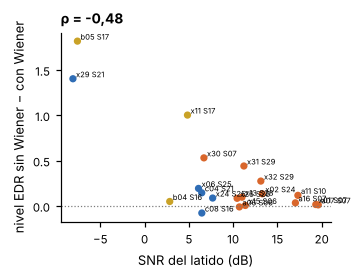

In [15]:
def snr_latido(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    f, s_s, s_n = estimate_psds(extract_realizations(x, record_beats(rec)["t_r"] * fs, fs), fs, WIENER_TEMPLATE)
    return 10 * np.log10(s_s.sum() / s_n.sum())


with ProcessPoolExecutor(4) as ex:
    w_["SNR del latido (dB)"] = pd.Series(dict(zip(TEST, ex.map(snr_latido, TEST))))
r_snr = spearmanr(w_["SNR del latido (dB)"], w_.cambio)[0]
print(f"ρ entre la SNR del latido y el cambio del nivel de la EDR sin Wiener: {r_snr:.3f}")
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.scatter(w_["SNR del latido (dB)"], w_.cambio, s=14, c=[COLORES_CAT[c] for c in w_["categoría"]])
for r_, f_ in w_.iterrows():
    ax.annotate(f"{r_} {f_.persona}", (f_["SNR del latido (dB)"], f_.cambio), fontsize=5, xytext=(2, 1), textcoords="offset points")
ax.axhline(0, color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="SNR del latido (dB)", ylabel="nivel EDR sin Wiener − con Wiener", title=f"ρ = {r_snr:.2f}".replace(".", ","))
fig.tight_layout()
save(fig, "12_snr_wiener")
w_.sort_values("SNR del latido (dB)")[["persona", "categoría", "apnea real (%)", "SNR del latido (dB)", "cambio", "puesto con Wiener", "puesto sin Wiener"]].round(2)

**Qué se ve.**
- **Las dos noches con el latido más ruidoso de test son las dos que más subieron sin Wiener:** b05 (−7,6 dB) y x29 (−8,1 dB). En ellas el ruido tiene más potencia que el latido.
- **x11** (4,8 dB, misma persona que b05) es la tercera que más subió.
- **La SNR no lo explica todo:** b04 (2,8 dB) casi no cambió. Entre la SNR y el cambio, ρ = −0,48.
- **Es compatible con que el Wiener protegía la EDR del ruido sobre el QRS en esas noches.** Sin él, el ruido entra en el área del QRS, sube la potencia de la EDR en la banda y la noche parece tener mucha apnea. Es una lectura posterior y con pocas noches: no se puso a prueba.
- **Cómo se había decidido sacarlo:** en desarrollo (`07` §9) el Wiener no mejoraba ninguna medida de forma demostrable, y salió por el criterio de sencillez. No se lo consideró una etapa protectora, así que no pasó por el criterio de robustez de `08`, que evalúa esas etapas con pruebas de estrés. Queda como limitación. No se puede volver a ponerlo por lo que se vio en test.

### 4.5 El nivel de la EDR y el tipo de persona

La limitación 12 de `objetivos_hipotesis.md` dice que el nivel de la EDR también acompaña a la edad y al índice de masa corporal (IMC), que a su vez van con la cantidad de apnea. Se mira acá con las noches de test y de desarrollo. Las noches de una misma persona tienen el mismo perfil, así que son descriptivas y no independientes.

In [16]:
filas = []
for nombre, N_ in (("desarrollo", ND), ("test", NT)):
    N_ = N_.join(PERFIL[["age", "IMC"]])
    N_["residuo EDR"] = N_["nivel EDR"] - np.polyval(recta, N_["apnea real (%)"])
    filas.append({"base": nombre, "noches": len(N_),
                  "ρ (nivel EDR, % apnea)": spearmanr(N_["nivel EDR"], N_["apnea real (%)"])[0],
                  "ρ (nivel EDR, IMC)": spearmanr(N_["nivel EDR"], N_.IMC)[0],
                  "ρ (nivel EDR, edad)": spearmanr(N_["nivel EDR"], N_.age)[0],
                  "ρ (IMC, % apnea)": spearmanr(N_.IMC, N_["apnea real (%)"])[0],
                  "ρ (residuo EDR, IMC)": spearmanr(N_["residuo EDR"], N_.IMC)[0]})
print("residuo EDR: nivel de la EDR menos el que le correspondería por su % de apnea según la recta de desarrollo")
pd.DataFrame(filas).set_index("base").round(3)

residuo EDR: nivel de la EDR menos el que le correspondería por su % de apnea según la recta de desarrollo


,noches,"ρ (nivel EDR, % apnea)","ρ (nivel EDR, IMC)","ρ (nivel EDR, edad)","ρ (IMC, % apnea)","ρ (residuo EDR, IMC)"
base,,,,,,
desarrollo,47,0.784,0.677,0.557,0.755,0.173
test,20,0.531,0.552,0.058,0.513,-0.053


In [17]:
NTp = NT.join(PERFIL[["age", "sex", "IMC"]])
NTp["residuo EDR"] = NTp["nivel EDR"] - np.polyval(recta, NTp["apnea real (%)"])
NTp[["persona", "categoría", "apnea real (%)", "nivel EDR", "residuo EDR", "IMC", "age", "sex", "error (puntos)"]].sort_values("residuo EDR").round(2)

,persona,categoría,apnea real (%),nivel EDR,residuo EDR,IMC,age,sex,error (puntos)
record,,,,,,,,,
a11,S10,A,47.84,-2.84,-0.95,36.49,58,M,-47.84
x32,S29,A,79.17,-1.94,-0.46,29.86,29,F,5.44
x31,S29,A,92.95,-1.70,-0.40,29.86,29,F,5.06
a06,S06,A,40.71,-2.36,-0.38,32.46,63,M,-35.38
x24,S25,C,0.24,-2.89,-0.37,22.84,31,M,-0.24
x15,S06,A,40.32,-2.28,-0.29,32.46,63,M,-37.10
x26,S28,A,66.60,-1.89,-0.24,33.17,57,M,-37.09
x01,S07,A,73.67,-1.78,-0.23,33.52,44,M,-13.16
x06,S25,C,0.00,-2.60,-0.08,22.84,31,M,7.03


**Qué se ve.**
- **En las dos bases el nivel de la EDR acompaña al IMC** (ρ = 0,68 en desarrollo y 0,55 en test). Pero el IMC también acompaña al % de apnea (0,76 y 0,51).
- **El residuo no acompaña al IMC** (0,17 y −0,05). El residuo es cuánto se aparta el nivel de lo esperado por la apnea de la noche.
- **En test la edad casi no se relaciona con el nivel** (0,06; en desarrollo, 0,56).
- **Los residuos más grandes son de personas con IMC alto, pero en sentidos opuestos:**
  - S17 (IMC 41,7) tiene los dos residuos positivos más grandes (b05 y x11);
  - S10 (IMC 36,5) tiene el negativo más grande (a11).

  Con estos datos no se puede decir que el IMC explique los errores del nivel de la EDR.

## 5. Nivel persona

El bootstrap sortea personas, porque las noches y los minutos de una misma persona no son independientes. Esta tabla junta las noches de cada persona.

In [18]:
filas = []
for u, g_ in et.groupby("subject"):
    m_ = metricas(g_.label, g_.decision)
    filas.append({"persona": u, "noches": ", ".join(sorted(g_.record.unique())),
                  "categorías": "".join(sorted(g_.category.unique())), "minutos evaluados": len(g_),
                  "% de los minutos de test": 100 * len(g_) / len(et), "apnea real (%)": 100 * g_.label.mean(),
                  "marcado (%)": 100 * g_.decision.mean(), "exactitud": m_["exactitud"],
                  "sensibilidad": m_["sensibilidad"] if g_.label.sum() else np.nan, "especificidad": m_["especificidad"],
                  "IMC": PERFIL.IMC[g_.record.iloc[0]], "edad": PERFIL.age[g_.record.iloc[0]]})
NP = pd.DataFrame(filas).set_index("persona")
print(f"exactitud por persona: mediana {NP.exactitud.median():.3f}, de {NP.exactitud.min():.3f} a {NP.exactitud.max():.3f}")
NP.sort_values("exactitud").round(3)

exactitud por persona: mediana 0.816, de 0.522 a 0.969


,noches,categorías,minutos evaluados,% de los minutos de test,apnea real (%),marcado (%),exactitud,sensibilidad,especificidad,IMC,edad
persona,,,,,,,,,,,
S10,a11,A,464,5.246,47.845,0.000,0.522,0.000,1.000,36.494,58
S06,"a06, x15",A,1002,11.330,40.519,4.291,0.620,0.084,0.985,32.458,63
S28,"x13, x26",A,1019,11.522,62.120,30.520,0.625,0.444,0.922,33.173,57
S17,"b05, x11",B,831,9.396,7.942,36.823,0.702,0.939,0.681,41.667,52
S07,"a07, a16, x01, x30",A,2001,22.626,66.917,71.514,0.768,0.861,0.580,33.515,44
S16,"b04, c08",BC,926,10.470,1.080,13.607,0.864,0.500,0.868,19.753,42
S24,x02,A,467,5.280,44.754,56.317,0.884,1.000,0.791,24.741,46
S29,"x31, x32",A,1086,12.280,86.188,91.436,0.931,0.990,0.560,29.861,29
S25,"x06, x24",C,853,9.645,0.117,3.634,0.962,0.000,0.964,22.837,31


**Qué se ve.**
- La exactitud por persona va de 0,52 (S10) a 0,97 (S21), con mediana 0,82.
- **Las tres personas con peor exactitud** (S10, S06 y S28) son las de las noches subestimadas, y juntas tienen el 28 % de los minutos de test.
- **S17, la persona de b05 y x11, es la única sobreestimada en serio:** marca el 37 % de sus minutos y tiene el 8 % de apnea.
- **Estas cuatro personas explican por qué los intervalos de test son tan anchos** (por ejemplo, la sensibilidad va de 0,30 a 0,91), porque el bootstrap sortea personas.

## 6. Los errores, explicados con las señales

### 6.1 Qué acompaña al error de cada noche

Como en `06` §2, ahora con el detector final. El error de cada noche se compara con dos cantidades que son propiedades de la noche o de la persona:
- el **residuo de la EDR**: cuánto se aparta el término EDR de la noche del que le correspondería por su % de apnea según la recta de desarrollo;
- el **término RR en los minutos normales**: personas cuyo RR oscila mucho o poco en la banda aunque no tengan apnea.

Se dejan afuera las noches con menos de la mitad de los minutos evaluados (c04 y x29), igual que en `06`.

residuo término EDR: ρ con el error 0.802 en test y 0.548 en desarrollo
término RR, minutos normales: ρ con el error 0.585 en test y 0.352 en desarrollo


PosixPath('/home/user/TP-PSB-G8/informe/figuras/12_error_causas.png')

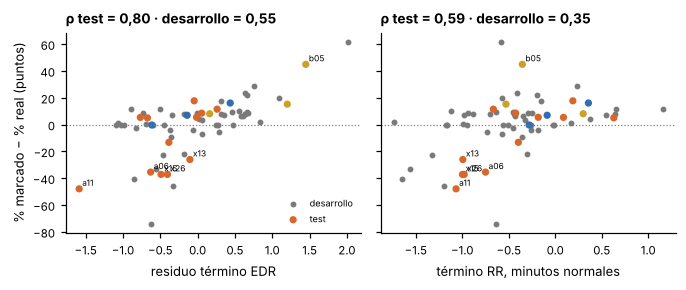

In [19]:
recta_t = np.polyfit(ND["apnea real (%)"], ND["término EDR"], 1)
for N_ in (NT, ND):
    N_["residuo término EDR"] = N_["término EDR"] - np.polyval(recta_t, N_["apnea real (%)"])
con = NT[NT["evaluados (%)"] >= 50]
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.7), sharey=True)
for ax, col in zip(axs, ("residuo término EDR", "término RR, minutos normales")):
    rt, rd = spearmanr(con[col], con["error (puntos)"])[0], spearmanr(ND[col], ND["error (puntos)"])[0]
    ax.scatter(ND[col], ND["error (puntos)"], s=8, color=GRIS, label="desarrollo")
    ax.scatter(con[col], con["error (puntos)"], s=14, c=[COLORES_CAT[c] for c in con["categoría"]], label="test")
    for r_, f_ in con.iterrows():
        if abs(f_["error (puntos)"]) > 20:
            ax.annotate(r_, (f_[col], f_["error (puntos)"]), fontsize=5.5, xytext=(2, 2), textcoords="offset points")
    ax.axhline(0, color=GRIS, ls=":", lw=0.8)
    ax.set(xlabel=col, title=f"ρ test = {rt:.2f} · desarrollo = {rd:.2f}".replace(".", ","))
    print(f"{col}: ρ con el error {rt:.3f} en test y {rd:.3f} en desarrollo")
axs[0].set_ylabel("% marcado − % real (puntos)")
axs[0].legend(fontsize=6, loc="lower right")
fig.tight_layout()
save(fig, "12_error_causas")

**Qué se ve.**
- **El error de cada noche acompaña a dos cantidades:**
  - al residuo del término EDR: ρ = 0,80 en test y 0,55 en desarrollo;
  - al término RR en los minutos normales: 0,59 y 0,35.
- **Es el mismo patrón que encontró `06` con la versión evaluada** (0,67 y 0,75 en test): los errores dependen de la noche o de la persona, no del minuto.
- **Con el detector final pesa más el nivel de la EDR.**

### 6.2 Las noches donde más falla, minuto a minuto

Las noches se eligen con una regla, no a mano: las tres noches más subestimadas de personas distintas, la más sobreestimada, el control con más minutos marcados y, como referencia, la noche A con mayor exactitud. Cada panel muestra el término RR de cada minuto (naranja con apnea, azul normal) y la vara de la noche: se marcan los minutos por encima de la línea.

,por qué se eligió,persona,apnea real (%),marcado (%),término EDR,vara del RR,"término RR, minutos normales","término RR, minutos con apnea",AUC dentro de la noche
record,,,,,,,,,
a11,subestimada,S10,47.84,0.00,-1.42,1.90,-1.07,-0.44,0.85
x15,subestimada,S06,40.32,3.23,-0.49,0.97,-1.00,-0.06,0.83
x26,subestimada,S28,66.60,29.51,0.18,0.30,-0.98,0.15,0.86
b05,sobreestimada,S17,13.95,58.95,0.87,-0.39,-0.35,0.56,0.84
c08,control con más marcado,S16,0.00,16.14,-0.45,0.93,0.36,NaN,NaN
x31,referencia: la noche A con mayor exactitud,S29,92.95,98.01,0.49,-0.01,0.63,1.81,0.97


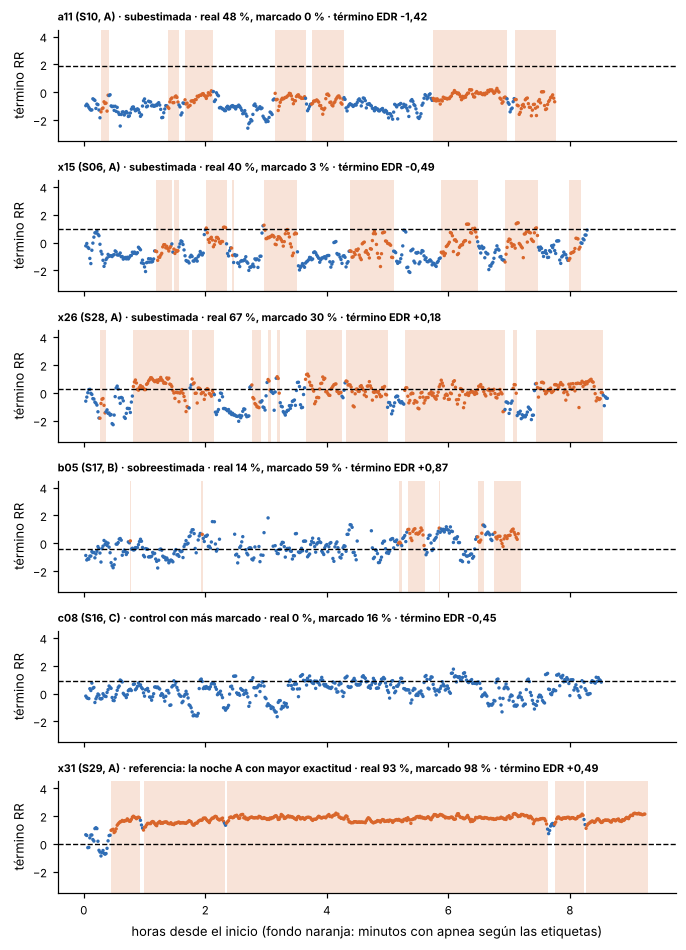

In [20]:
ok = NT[NT["evaluados (%)"] >= 50].copy()
ok["sub"] = ok["apnea real (%)"] - ok["marcado (%)"]
CASOS, vistos = [], set()
for r_, f_ in ok.sort_values("sub", ascending=False).iterrows():
    if f_["sub"] > 0 and f_.persona not in vistos and len(CASOS) < 3:
        CASOS.append((r_, "subestimada")); vistos.add(f_.persona)
for r_, motivo in ((ok["sub"].idxmin(), "sobreestimada"), (ok[ok["categoría"] == "C"]["marcado (%)"].idxmax(), "control con más marcado"),
                   (ok[ok["categoría"] == "A"].exactitud.idxmax(), "referencia: la noche A con mayor exactitud")):
    if r_ not in [c_[0] for c_ in CASOS]:
        CASOS.append((r_, motivo))

fig, axs = plt.subplots(len(CASOS), 1, figsize=(ANCHO, 1.45 * len(CASOS)), sharex=True)
for ax, (r_, motivo) in zip(axs, CASOS):
    g_ = et[et.record == r_].sort_values("minute")
    shade_apnea(ax, load_apnea_labels(r_), unit=60, label=None)
    f_ = NT.loc[r_]
    ax.set_title(f"{r_} ({f_.persona}, {f_['categoría']}) · {motivo} · real {f_['apnea real (%)']:.0f} %, "
                 f"marcado {f_['marcado (%)']:.0f} % · término EDR {f_['término EDR']:+.2f}".replace(".", ","), fontsize=7)
    ax.scatter(g_.minute / 60, g_.termino_rr, s=1.5, c=np.where(g_.label == 1, APNEA, NORMAL))
    ax.axhline(f_["vara del RR"], color="black", ls="--", lw=0.9)
    ax.set(ylabel="término RR", ylim=(-3.5, 4.5))
axs[-1].set_xlabel("horas desde el inicio (fondo naranja: minutos con apnea según las etiquetas)")
fig.tight_layout()
save(fig, "12_casos")
pd.DataFrame(CASOS, columns=["record", "por qué se eligió"]).set_index("record").join(
    NT[["persona", "apnea real (%)", "marcado (%)", "término EDR", "vara del RR", "término RR, minutos normales",
        "término RR, minutos con apnea", "AUC dentro de la noche"]]).round(2)

**Qué se ve.**
- **a11:** el RR sube en cada episodio (naranja), pero la vara está en 1,90 por el nivel bajo de la EDR, y ningún minuto la alcanza.
- **x15 (y a06, la misma persona):** durante la apnea el RR sube hasta cerca de 1, justo en la vara (0,97), y se marcan muy pocos minutos.
- **x26:** la vara es baja (0,30), pero el RR de muchos minutos con apnea queda entre 0 y 1, alrededor de ella. Se detecta la mitad.
- **b05:** el término EDR es el más alto de test y la vara queda en −0,39. El RR de casi toda la noche la supera, también en las horas sin apnea.
- **c08:** el RR de esta persona oscila cerca de la vara toda la noche, sin apnea, y se marca el 16 %.
- **x31:** en los minutos con apnea el término RR está cerca de 2, muy por encima de la vara, y se detectan casi todos.

### 6.3 Las señales de un minuto

Para la noche más subestimada y la noche de referencia, la serie RR y la EDR en la ventana de 240 s de un minuto con apnea típico de esa noche (el de término RR mediano entre sus minutos con apnea), y a la derecha la potencia de la EDR en todas las ventanas de la noche con su mediana, que es el nivel nocturno.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/12_senales.png')

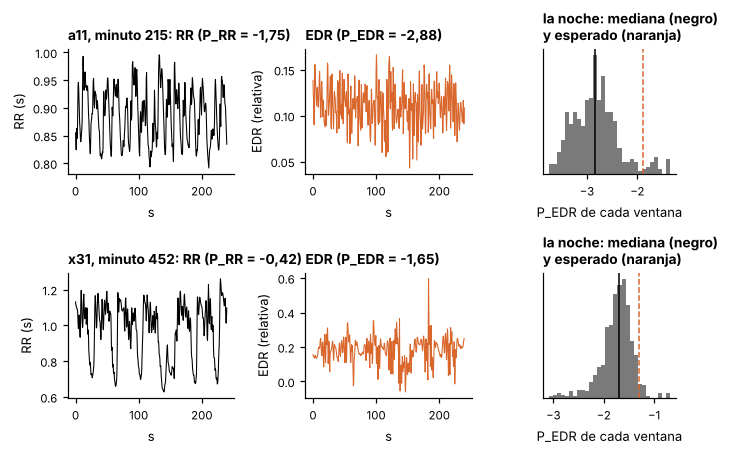

In [21]:
def minuto_tipico(r_):
    g_ = et[(et.record == r_) & (et.label == 1)]
    return int(g_.loc[(g_.termino_rr - g_.termino_rr.median()).abs().idxmin(), "minute"])


PAR = [CASOS[0][0], CASOS[-1][0]]
fig, axs = plt.subplots(len(PAR), 3, figsize=(ANCHO, 2.1 * len(PAR)), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for fila, r_ in zip(axs, PAR):
    an = analizar_noche(r_, version="final")
    m = minuto_tipico(r_)
    v = ventana_minuto(an, m)
    assert np.isclose(v["P_RR"], v["fila"].P_RR) and np.isclose(v["P_EDR"], v["fila"].P_EDR)
    tt = v["t"] - v["t"][0]
    fila[0].plot(tt, v["rr"], color="black", lw=0.7)
    fila[0].set(xlabel="s", ylabel="RR (s)", title=f"{r_}, minuto {m}: RR (P_RR = {v['P_RR']:.2f})".replace(".", ","))
    fila[1].plot(tt, v["edr"], color=APNEA, lw=0.7)
    fila[1].set(xlabel="s", ylabel="EDR (relativa)", title=f"EDR (P_EDR = {v['P_EDR']:.2f})".replace(".", ","))
    tab_r = T[T.record == r_]
    fila[2].hist(tab_r.P_EDR.dropna(), bins=30, color=GRIS)
    fila[2].axvline(tab_r.EDR_noche.iloc[0], color="black", lw=1)
    fila[2].axvline(np.polyval(recta, NT.loc[r_, "apnea real (%)"]), color=APNEA, ls="--", lw=1)
    fila[2].set(xlabel="P_EDR de cada ventana", yticks=[], title="la noche: mediana (negro)\ny esperado (naranja)")
fig.tight_layout()
save(fig, "12_senales")

**Qué se ve.**
- **a11:**
  - la serie RR del minuto con apnea oscila de forma marcada, pero la EDR no muestra un ciclo claro y su potencia en la banda es baja (P_EDR = −2,88);
  - en toda la noche pasa lo mismo: el nivel nocturno (−2,84) queda muy por debajo del esperado para su apnea según la recta de desarrollo.
- **x31:** el nivel también queda algo por debajo de lo esperado, pero su RR está tan arriba de la vara que no importa.

## 7. Los minutos que no se evalúan

Un minuto no se evalúa si no tiene etiqueta o si más del 20 % de sus RR quedaron corregidos por la limpieza (señal perdida o ritmo irregular).

In [22]:
exc = T.groupby("record").agg(minutos=("minute", "size"), sin_etiqueta=("label", lambda s_: 100 * (s_ < 0).mean()),
                              rr_corregidos=("q", lambda s_: 100 * (s_ > MINUTE_MAX_CORRECTED).mean()),
                              q_mediana=("q", "median"))
exc = exc.rename(columns={"sin_etiqueta": "sin etiqueta (%)", "rr_corregidos": "con > 20 % de RR corregidos (%)",
                          "q_mediana": "RR corregidos por minuto (mediana)"}).join(NT[["persona", "categoría", "evaluados (%)"]])
print(f"minutos evaluados: {len(et)} de {len(T)} ({100 * len(et) / len(T):.1f} %)")
exc.sort_values("evaluados (%)").head(6).round(2)

minutos evaluados: 8844 de 9639 (91.8 %)


,minutos,sin etiqueta (%),con > 20 % de RR corregidos (%),RR corregidos por minuto (mediana),persona,categoría,evaluados (%)
record,,,,,,,
x29,463,0.0,85.10,0.42,S21,C,14.90
c04,464,0.0,72.84,0.39,S21,C,27.16
b05,428,0.0,11.21,0.09,S17,B,88.79
x24,416,0.0,0.96,0.00,S25,C,99.04
b04,422,0.0,0.71,0.00,S16,B,99.05
x06,444,0.0,0.68,0.00,S25,C,99.32


**Qué se ve.**
- Se evalúan 8844 de 9639 minutos (91,8 %).
- **Casi todos los excluidos son de S21:** en x29 y c04, el 85 % y el 73 % de los minutos tienen más de 20 % de RR corregidos. Es la persona con un ritmo muy irregular que describe `06` §3.
- **b05 tiene excluido el 11 % de sus minutos,** y es una de las dos noches con el latido más ruidoso (§4.4).
- Ninguna otra noche pierde más del 1 %.

## 8. Con y sin Wiener, minuto a minuto y noche por noche

Las dos versiones evalúan los mismos minutos. Acá se ve en qué minutos deciden distinto y qué pasa en cada noche.

In [23]:
cm = et[["record", "minute", "label", "decision"]].merge(et_ev[["record", "minute", "decision"]], on=["record", "minute"],
                                                          suffixes=("_final", "_wiener"))
dist = cm[cm.decision_final != cm.decision_wiener]
gana_f = int((dist.decision_final == dist.label).sum())
print(f"deciden distinto en {len(dist)} de {len(cm)} minutos ({100 * len(dist) / len(cm):.1f} %): "
      f"acierta el final en {gana_f} y la versión con Wiener en {len(dist) - gana_f}")
nn = cm.groupby("record").agg(apnea_real=("label", "mean"), marcado_final=("decision_final", "mean"),
                              marcado_wiener=("decision_wiener", "mean"),
                              distintos=("decision_final", lambda s_: int((s_ != cm.loc[s_.index, "decision_wiener"]).sum())))
nn[["apnea_real", "marcado_final", "marcado_wiener"]] *= 100
nn["exactitud final"] = cm.assign(ok=cm.decision_final == cm.label).groupby("record").ok.mean()
nn["exactitud con Wiener"] = cm.assign(ok=cm.decision_wiener == cm.label).groupby("record").ok.mean()
nn = nn.rename(columns={"apnea_real": "apnea real (%)", "marcado_final": "marcado final (%)", "marcado_wiener": "marcado con Wiener (%)",
                        "distintos": "minutos con decisión distinta"}).join(w_[["persona", "categoría", "cambio"]].rename(columns={"cambio": "cambio del nivel EDR"}))
nn.sort_values("minutos con decisión distinta", ascending=False).round(2)

deciden distinto en 933 de 8844 minutos (10.5 %): acierta el final en 444 y la versión con Wiener en 489


,apnea real (%),marcado final (%),marcado con Wiener (%),minutos con decisión distinta,exactitud final,exactitud con Wiener,persona,categoría,cambio del nivel EDR
record,,,,,,,,,
b05,13.95,58.95,0.00,224,0.55,0.86,S17,B,1.82
x30,64.05,69.55,43.61,132,0.74,0.67,S07,A,0.53
c08,0.00,16.14,41.73,130,0.84,0.58,S16,C,-0.08
x11,2.88,18.18,0.00,82,0.83,0.97,S17,B,1.00
x01,73.67,60.51,72.10,59,0.75,0.79,S07,A,0.02
b04,2.39,10.53,22.25,49,0.89,0.80,S16,B,0.05
x13,57.54,31.55,41.07,48,0.68,0.74,S28,A,0.10
a07,63.04,80.83,89.33,43,0.76,0.72,S07,A,0.01
x26,66.60,29.51,37.86,43,0.57,0.63,S28,A,0.09


**Qué se ve.**
- **Las dos versiones deciden distinto en 933 minutos (10,5 %).** El final acierta en 444 y la versión con Wiener en 489: casi un empate.
- **Las diferencias se concentran en pocas noches y van en sentidos opuestos:**
  - con Wiener se acierta más en las dos noches de S17: b05 (exactitud 0,86 contra 0,55) y x11 (0,97 contra 0,83);
  - sin Wiener se acierta más en c08 (0,84 contra 0,58), b04 (0,89 contra 0,80) y x30 (0,74 contra 0,67).
- **En las noches subestimadas** (a11, a06, x15, x26 y x13) las dos versiones fallan casi igual. Sacar el Wiener no causó esos errores ni los habría arreglado.

## 9. Desarrollo y test (nivel base)

Test da algo peor que la validación cruzada de desarrollo en casi todas las medidas (`11` §4.4). ¿En qué se diferencian las dos bases? Se comparan el perfil de las personas y las dos cantidades que fijan la vara de cada noche.

medianas por persona (una fila por persona)


,personas,edad,IMC,mujeres
set,,,,
dev,19,44.0,27.4,2
test,10,45.0,31.2,2


,desarrollo,test
"nivel EDR, noches con < 5 % de apnea",-2.709,-2.259
"nivel EDR, noches con ≥ 40 % de apnea",-1.691,-1.803
término RR en minutos normales (mediana de las noches),-0.452,-0.411
término RR en minutos con apnea (mediana de las noches),0.637,0.618


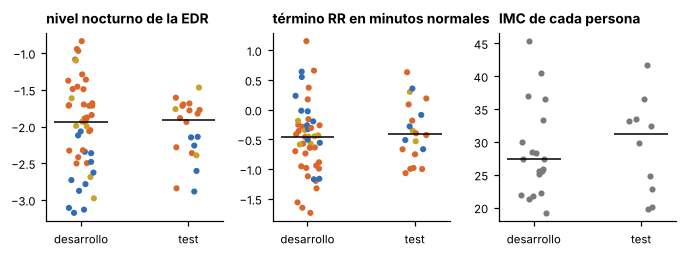

In [24]:
pers = split.drop_duplicates("subject").set_index("record").join(PERFIL)
perfil = pers.groupby("set").agg(personas=("subject", "size"), edad=("age", "median"), IMC=("IMC", "median"),
                                 mujeres=("sex", lambda s_: int((s_ == "F").sum())))
print("medianas por persona (una fila por persona)")
display(perfil.round(1))

fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.4))
for k, (col, titulo) in enumerate((("nivel EDR", "nivel nocturno de la EDR"), ("término RR, minutos normales", "término RR en minutos normales"))):
    for j, (N_, nombre) in enumerate(((ND, "desarrollo"), (NT, "test"))):
        xs = j + np.random.default_rng(k).uniform(-0.12, 0.12, len(N_))
        axs[k].scatter(xs, N_[col], s=9, c=[COLORES_CAT[c] for c in N_["categoría"]])
        axs[k].hlines(N_[col].median(), j - 0.25, j + 0.25, color="black", lw=1)
    axs[k].set(xticks=[0, 1], xticklabels=["desarrollo", "test"], title=titulo)
for j, (s_, nombre) in enumerate((("dev", "desarrollo"), ("test", "test"))):
    v_ = pers[pers.set == s_].IMC
    axs[2].scatter(j + np.random.default_rng(9).uniform(-0.12, 0.12, len(v_)), v_, s=9, color=GRIS)
    axs[2].hlines(v_.median(), j - 0.25, j + 0.25, color="black", lw=1)
axs[2].set(xticks=[0, 1], xticklabels=["desarrollo", "test"], title="IMC de cada persona")
fig.tight_layout()
save(fig, "12_desarrollo_test")
comp = pd.DataFrame({b: {"nivel EDR, noches con < 5 % de apnea": N_[N_["apnea real (%)"] < 5]["nivel EDR"].median(),
                         "nivel EDR, noches con ≥ 40 % de apnea": N_[N_["apnea real (%)"] >= 40]["nivel EDR"].median(),
                         "término RR en minutos normales (mediana de las noches)": N_["término RR, minutos normales"].median(),
                         "término RR en minutos con apnea (mediana de las noches)": N_["término RR, minutos con apnea"].median()}
                     for b, N_ in (("desarrollo", ND), ("test", NT))})
comp.round(3)

**Qué se ve.**
- **Las personas de test tienen un IMC mediano mayor** que las de desarrollo (31,2 contra 27,4), con una edad parecida (45 y 44 años).
- **El término RR se reparte igual en las dos bases,** tanto en los minutos normales (−0,41 y −0,45) como en los minutos con apnea (0,62 y 0,64).
- **El nivel de la EDR no se reparte igual:**
  - en las noches con poca apnea es más alto en test (−2,26 contra −2,71);
  - en las noches con mucha apnea es algo más bajo (−1,80 contra −1,69).
- **En test el rango del nivel de la EDR queda comprimido.** Eso es compatible con que P2 y la exactitud bajen de desarrollo a test. El término RR, en cambio, se reparte igual.

## 10. Conclusión del análisis posterior

*Escrita después de correr este notebook. Es descriptiva: no cambia el resultado de `11` ni el detector.*

| Pregunta | Respuesta | Dónde |
|---|---|---|
| ¿El RR ubica la apnea dentro de la noche? | Sí, en todas las noches (AUC ≥ 0,74), también en las subestimadas | §3.4 |
| ¿Dónde están los errores? | En noches enteras. 5 noches de 3 personas concentran el 82 % de los minutos con apnea perdidos, y 5 noches, el 61 % de las falsas alarmas | §2.1, §5 |
| ¿Por qué se pierden minutos con apnea? | En personas cuyo RR responde poco al ciclo de la apnea (S06 y S28), y en una noche con el nivel de EDR de un control (a11, de S10). Pasa igual con y sin Wiener | §3.1, §6, §8 |
| ¿Por qué falla P2? | Sobre todo porque, sin Wiener, dos noches con poca apnea (b05 y x11, de S17) pasan a tener niveles de EDR altos, y porque a11 tiene un nivel de control. Sin S17, ρ = 0,67 | §4.1–4.3 |
| ¿Qué hacía el Wiener? | En las noches con el latido más ruidoso (b05 y x29), sin Wiener el nivel de la EDR sube mucho. Es compatible con que protegía la EDR del ruido, pero no se puso a prueba | §4.4 |
| ¿En qué se diferencia test de desarrollo? | Las personas de test tienen más IMC, y el nivel de la EDR tiene menos rango entre las noches con poca y con mucha apnea. El término RR se reparte igual | §9 |

**Para el informe** (y para responder a la devolución):
- **Mostrar los resultados por nivel,** cada uno con su figura: minuto (§2), noche (§3), persona (§5), categoría (§2.2 y §3.2) y base (§9).
- **Explicar los errores con las señales:** la vara de cada noche (§6.2) y las señales de un minuto (§6.3).
- **Decir que el detector final no sostiene la parte (b) en test, y por qué** (§4). Decir también que no se puede volver a la versión con Wiener.
- **Agregar una limitación:** el Wiener se sacó por el criterio de sencillez, sin pasar por el de robustez. En test, sin él, el nivel de la EDR de dos noches se vuelve sensible al ruido del latido.

**Qué no se hace con esto.** No se cambia el detector ni se elige otra versión. Para saber si el Wiener protege de verdad, o si otra medida nocturna estima mejor la cantidad de apnea, hace falta otra base.